# Step 2 — Holdout split + Stratified 5-fold CV

**DO THIS BEFORE ANY CLEANING.** Defining the validation scheme first is the leakage barrier.

**Study:** data leakage, stratified vs. plain K-fold, why a 1:14 imbalance needs stratification.

**Why stratification here:** with only 6.68% defaults, plain `KFold` can give folds very different default shares (e.g. 5% vs 9%). That makes KS and WoE unstable because some bins have too few bad cases. `StratifiedKFold` keeps ~6.68% in every fold, so fold-to-fold spread measures **model stability**, not split luck. It does **not** prevent leakage — the Pipeline fitted inside each fold does that.

**Build:** stratified 70/30 holdout (seed 42) → `train.csv` / `test.csv`. Lock the test set. On train only, define `StratifiedKFold(5, shuffle=True, random_state=42)` and print default count/rate per fold.

**Verify:** each fold within ±0.5pp of 6.68%, >100 defaults per fold, train/test indices disjoint.

**Save:** `reports/tables/fold_summary.csv`, `reports/figures/fold_default_rates.png`. Use prompt 2 in `prompts.md`. **Do not clean, impute, cap, or bin yet.**

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from src import config

# Constants from Step 1 EDA (full-file target rate = 10,026 / 150,000)
EXPECTED_RATE = 6.684
TOL_PP = 0.5

df = pd.read_csv(config.RAW_FILE)
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed:')])
print('Raw shape after dropping index column:', df.shape)

Raw shape after dropping index column: (150000, 11)


In [2]:
# Stratified 70/30 holdout. The test set is LOCKED after this cell:
# only its row count is reported, to confirm the split ratio.
train, test = train_test_split(
    df,
    test_size=config.TEST_SIZE,
    stratify=df[config.TARGET],
    random_state=config.RANDOM_SEED,
)

assert set(train.index).isdisjoint(test.index), 'train/test index overlap'
assert round(len(test) / len(df), 2) == config.TEST_SIZE

train.to_csv(config.TRAIN_FILE, index=False)
test.to_csv(config.TEST_FILE, index=False)

print(f'Train rows: {len(train):,} ({len(train)/len(df)*100:.0f}%)')
print(f'Test rows:  {len(test):,} (written to disk, NOT analysed)')
print(f'Train default rate: {train[config.TARGET].mean()*100:.3f}%')
print('Saved:', config.TRAIN_FILE.name, 'and', config.TEST_FILE.name)

Train rows: 105,000 (70%)
Test rows:  45,000 (written to disk, NOT analysed)
Train default rate: 6.684%
Saved: train.csv and test.csv


In [3]:
# Stratified 5-fold CV on TRAIN ONLY. No test data enters this cell.
y_train = train[config.TARGET]
X_train = train.drop(columns=[config.TARGET])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_SEED)

rows = []
for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
    y_val = y_train.iloc[va_idx]
    n = len(y_val)
    n_default = int(y_val.sum())
    rate = n_default / n * 100

    assert set(tr_idx).isdisjoint(va_idx), f'fold {fold}: train/val overlap'
    assert n_default > 100, f'fold {fold}: too few defaults ({n_default})'
    assert abs(rate - EXPECTED_RATE) <= TOL_PP, f'fold {fold}: rate {rate:.3f}% outside tolerance'

    rows.append({
        'fold': fold,
        'n_validation_rows': n,
        'n_defaults': n_default,
        'default_rate_pct': round(rate, 3),
        'deviation_pp': round(rate - EXPECTED_RATE, 3),
    })

fold_summary = pd.DataFrame(rows)
fold_summary.to_csv(config.TABLES / 'fold_summary.csv', index=False)
fold_summary

,fold,n_validation_rows,n_defaults,default_rate_pct,deviation_pp
0,1,21000,1403,6.681,-0.003
1,2,21000,1403,6.681,-0.003
2,3,21000,1404,6.686,0.002
3,4,21000,1404,6.686,0.002
4,5,21000,1404,6.686,0.002


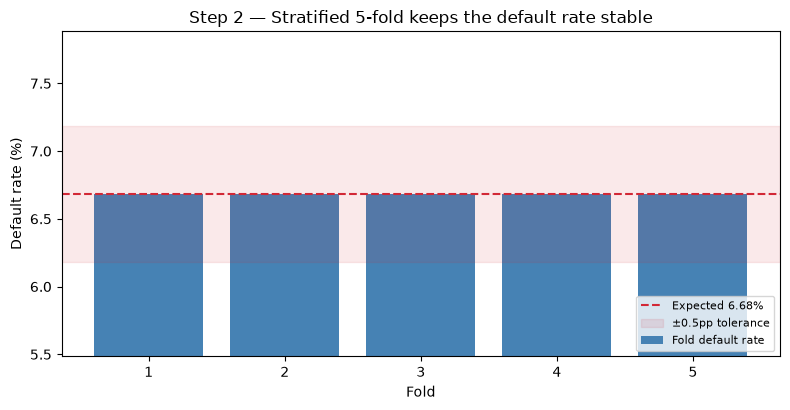

In [4]:
# Visual proof that every fold keeps the ~6.68% default rate
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(fold_summary['fold'].astype(str), fold_summary['default_rate_pct'],
       color='steelblue', label='Fold default rate')
ax.axhline(EXPECTED_RATE, color='#D22836', ls='--', lw=1.5,
           label=f'Expected {EXPECTED_RATE:.2f}%')
ax.axhspan(EXPECTED_RATE - TOL_PP, EXPECTED_RATE + TOL_PP,
           color='#D22836', alpha=0.10, label=f'±{TOL_PP}pp tolerance')
ax.set_ylim(EXPECTED_RATE - 1.2, EXPECTED_RATE + 1.2)
ax.set_xlabel('Fold')
ax.set_ylabel('Default rate (%)')
ax.set_title('Step 2 — Stratified 5-fold keeps the default rate stable')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
fig.savefig(config.FIGURES / 'fold_default_rates.png', dpi=110, bbox_inches='tight')
plt.show()

## Findings

- **Split:** 105,000 training rows (70%) and 45,000 test rows (30%). The training default rate is 6.684%, identical to the full file, so stratification preserved the class balance. The test set was written to disk and locked — no target or feature statistic was computed on it.
- **Folds:** all 5 folds contain 21,000 validation rows with 1,403–1,404 defaults, giving rates of 6.681–6.686%. The largest deviation from 6.684% is 0.003pp, far inside the ±0.5pp tolerance — plain K-fold would not be this consistent.

**Leakage check:** train/test indices asserted disjoint; each fold's train and validation indices asserted disjoint; every fold has >100 defaults. The fold loop reads `train.csv` only. No cleaning, imputation, capping, or binning has been applied — that comes in Step 3 inside the pipeline.